# Lab Sheet-09 · Project 1: COVID-19 Data Analysis Dashboard
**MCA III Semester (Session 2026–2027) – Mini Projects on Data Analytics and Visualization**

**Objective:** perform EDA, build meaningful visualizations and derive insights on confirmed cases, recoveries, deaths, vaccination trends and country-wise statistics.

## Datasets (Kaggle)
| Purpose | Dataset | Files used |
|---|---|---|
| Cases / deaths / recoveries | [COVID-19 Corona Virus Report (imdevskp)](https://www.kaggle.com/datasets/imdevskp/corona-virus-report) | `full_grouped.csv` |
| Vaccination | [COVID-19 World Vaccination Progress (gpreda)](https://www.kaggle.com/datasets/gpreda/covid-world-vaccination-progress) | `country_vaccinations.csv` |


**Workflow:** Load → EDA → Missing values → Visualizations → Dashboard → Findings

In [1]:
# !pip install -q pandas numpy matplotlib seaborn plotly
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

## 1. Load the data

In [2]:
full = pd.read_csv("full_grouped.csv", parse_dates=["Date"])
vac = pd.read_csv("country_vaccinations.csv", parse_dates=["date"])
print("cases :", full.shape, "| vaccination:", vac.shape)
full.head()

cases : (35156, 10) | vaccination: (86512, 15)


,Date,Country/Region,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,WHO Region
0,2020-01-22,Afghanistan,0,0,0,0,0,0,0,Eastern Mediterranean
1,2020-01-22,Albania,0,0,0,0,0,0,0,Europe
2,2020-01-22,Algeria,0,0,0,0,0,0,0,Africa
3,2020-01-22,Andorra,0,0,0,0,0,0,0,Europe
4,2020-01-22,Angola,0,0,0,0,0,0,0,Africa


## 2. Exploratory Data Analysis (EDA)

In [3]:
print(full.info())
display(full.describe().T.round(1))
print("Countries:", full['Country/Region'].nunique(),
      "| Date range:", full['Date'].min().date(), "->", full['Date'].max().date())

<class 'pandas.DataFrame'>
RangeIndex: 35156 entries, 0 to 35155
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Date            35156 non-null  datetime64[us]
 1   Country/Region  35156 non-null  str           
 2   Confirmed       35156 non-null  int64         
 3   Deaths          35156 non-null  int64         
 4   Recovered       35156 non-null  int64         
 5   Active          35156 non-null  int64         
 6   New cases       35156 non-null  int64         
 7   New deaths      35156 non-null  int64         
 8   New recovered   35156 non-null  int64         
 9   WHO Region      35156 non-null  str           
dtypes: datetime64[us](1), int64(7), str(2)
memory usage: 3.3 MB
None


,count,mean,min,25%,50%,75%,max,std
Date,35156,2020-04-24 12:00:00,2020-01-22 00:00:00,2020-03-08 18:00:00,2020-04-24 12:00:00,2020-06-10 06:00:00,2020-07-27 00:00:00,NaN
Confirmed,35156.0,23566.631073,0.0,1.0,250.0,3640.25,4290259.0,149981.835259
Deaths,35156.0,1234.068239,0.0,0.0,4.0,78.25,148011.0,7437.238354
Recovered,35156.0,11048.134856,0.0,0.0,33.0,1286.25,1846641.0,64546.400787
Active,35156.0,11284.427978,-2.0,0.0,85.0,1454.0,2816444.0,89971.494115
New cases,35156.0,469.36375,0.0,0.0,2.0,75.0,77255.0,3005.86754
New deaths,35156.0,18.603339,-1918.0,0.0,0.0,1.0,3887.0,115.706351
New recovered,35156.0,269.315593,-16298.0,0.0,0.0,20.0,140050.0,2068.063852


Countries: 187 | Date range: 2020-01-22 -> 2020-07-27


In [4]:
print("Vaccination data")
vac.info()
display(vac.head())

Vaccination data
<class 'pandas.DataFrame'>
RangeIndex: 86512 entries, 0 to 86511
Data columns (total 15 columns):
 #   Column                               Non-Null Count  Dtype         
---  ------                               --------------  -----         
 0   country                              86512 non-null  str           
 1   iso_code                             86512 non-null  str           
 2   date                                 86512 non-null  datetime64[us]
 3   total_vaccinations                   43607 non-null  float64       
 4   people_vaccinated                    41294 non-null  float64       
 5   people_fully_vaccinated              38802 non-null  float64       
 6   daily_vaccinations_raw               35362 non-null  float64       
 7   daily_vaccinations                   86213 non-null  float64       
 8   total_vaccinations_per_hundred       43607 non-null  float64       
 9   people_vaccinated_per_hundred        41294 non-null  float64       
 10  peop

,country,iso_code,date,total_vaccinations,people_vaccinated,people_fully_vaccinated,daily_vaccinations_raw,daily_vaccinations,total_vaccinations_per_hundred,people_vaccinated_per_hundred,people_fully_vaccinated_per_hundred,daily_vaccinations_per_million,vaccines,source_name,source_website
0,Afghanistan,AFG,2021-02-22,0.0,0.0,NaN,NaN,NaN,0.0,0.0,NaN,NaN,"Johnson&Johnson, Oxford/AstraZeneca, Pfizer/Bi...",World Health Organization,https://covid19.who.int/
1,Afghanistan,AFG,2021-02-23,NaN,NaN,NaN,NaN,1367.0,NaN,NaN,NaN,34.0,"Johnson&Johnson, Oxford/AstraZeneca, Pfizer/Bi...",World Health Organization,https://covid19.who.int/
2,Afghanistan,AFG,2021-02-24,NaN,NaN,NaN,NaN,1367.0,NaN,NaN,NaN,34.0,"Johnson&Johnson, Oxford/AstraZeneca, Pfizer/Bi...",World Health Organization,https://covid19.who.int/
3,Afghanistan,AFG,2021-02-25,NaN,NaN,NaN,NaN,1367.0,NaN,NaN,NaN,34.0,"Johnson&Johnson, Oxford/AstraZeneca, Pfizer/Bi...",World Health Organization,https://covid19.who.int/
4,Afghanistan,AFG,2021-02-26,NaN,NaN,NaN,NaN,1367.0,NaN,NaN,NaN,34.0,"Johnson&Johnson, Oxford/AstraZeneca, Pfizer/Bi...",World Health Organization,https://covid19.who.int/


## 3. Handle missing values & data quality
* **Cases data:** check nulls and negative daily counts (data corrections in the source produce negative "new" values) → clipped to 0.
* **Vaccination data:** cumulative columns are forward-filled **within each country** (a cumulative number cannot decrease, so the last known value is the best estimate); remaining gaps → 0 for daily figures.

In [5]:
miss = pd.concat([full.isna().sum().rename("cases_missing"),
                  vac.isna().sum().rename("vac_missing")], axis=1).fillna(0).astype(int)
display(miss[miss.sum(axis=1) > 0])

# ---- cases data
for col in ["New cases", "New deaths", "New recovered"]:
    if col in full:
        full[col] = full[col].clip(lower=0)
full = full.rename(columns={"Country/Region": "Country"})

# ---- vaccination data
vac = vac.sort_values(["country", "date"])
cum_cols = [c for c in ["total_vaccinations", "people_vaccinated", "people_fully_vaccinated",
                        "total_vaccinations_per_hundred", "people_fully_vaccinated_per_hundred"]
            if c in vac]
vac[cum_cols] = vac.groupby("country")[cum_cols].ffill()
vac["daily_vaccinations"] = vac["daily_vaccinations"].fillna(0)
vac[cum_cols] = vac[cum_cols].fillna(0)
print("Remaining nulls (vaccination):", int(vac[cum_cols + ['daily_vaccinations']].isna().sum().sum()))

,cases_missing,vac_missing
total_vaccinations,0,42905
people_vaccinated,0,45218
people_fully_vaccinated,0,47710
daily_vaccinations_raw,0,51150
daily_vaccinations,0,299
total_vaccinations_per_hundred,0,42905
people_vaccinated_per_hundred,0,45218
people_fully_vaccinated_per_hundred,0,47710
daily_vaccinations_per_million,0,299


Remaining nulls (vaccination): 0


## 4. Derived metrics

In [6]:
last_date = full["Date"].max()
latest = full[full["Date"] == last_date].copy()
latest["Fatality rate %"] = latest["Deaths"] / latest["Confirmed"].replace(0, np.nan) * 100
latest["Recovery rate %"] = latest["Recovered"] / latest["Confirmed"].replace(0, np.nan) * 100
latest["Active %"] = latest["Active"] / latest["Confirmed"].replace(0, np.nan) * 100

glob_ts = full.groupby("Date")[["Confirmed", "Deaths", "Recovered", "Active", "New cases", "New deaths"]].sum()
glob_ts["New cases 7d MA"] = glob_ts["New cases"].rolling(7).mean()
glob_ts["New deaths 7d MA"] = glob_ts["New deaths"].rolling(7).mean()

top10 = latest.nlargest(10, "Confirmed")
print("Snapshot date:", last_date.date())
display(top10[["Country", "Confirmed", "Deaths", "Recovered", "Active", "Fatality rate %", "Recovery rate %"]].round(2))

Snapshot date: 2020-07-27


,Country,Confirmed,Deaths,Recovered,Active,Fatality rate %,Recovery rate %
35142,US,4290259,148011,1325804,2816444,3.45,30.90
34992,Brazil,2442375,87618,1846641,508116,3.59,75.61
35048,India,1480073,33408,951166,495499,2.26,64.26
35107,Russia,816680,13334,602249,201097,1.63,73.74
35123,South Africa,452529,7067,274925,170537,1.56,60.75
35080,Mexico,395489,44022,303810,47657,11.13,76.82
35101,Peru,389717,18418,272547,98752,4.73,69.93
35004,Chile,347923,9187,319954,18782,2.64,91.96
35146,United Kingdom,301708,45844,1437,254427,15.19,0.48
35050,Iran,293606,15912,255144,22550,5.42,86.90


## 5. Visualizations
Each chart is followed by a one-line explanation of *why this chart type* and *what it shows*.

### 5.1 Global trend – line chart (best for change over time)

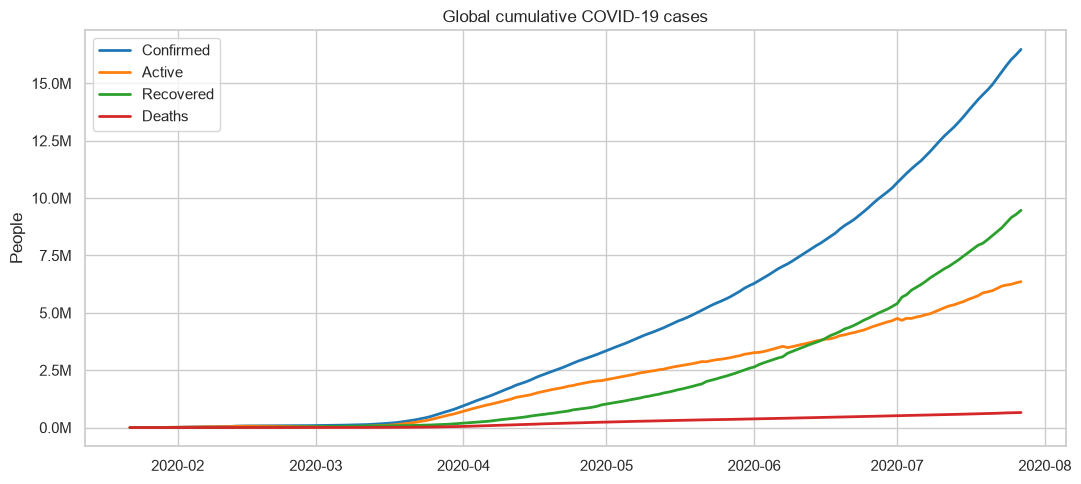

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
for col, color in zip(["Confirmed", "Active", "Recovered", "Deaths"], ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]):
    ax.plot(glob_ts.index, glob_ts[col], label=col, color=color, lw=2)
ax.set_title("Global cumulative COVID-19 cases"); ax.set_ylabel("People")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
ax.legend(); plt.tight_layout(); plt.show()

**Reading:** cumulative curves show the overall scale and growth phase; the gap between *Confirmed* and *Recovered + Deaths* is the *Active* burden on health systems.

### 5.2 Daily new cases & deaths – bars + 7-day moving average (smooths reporting noise)

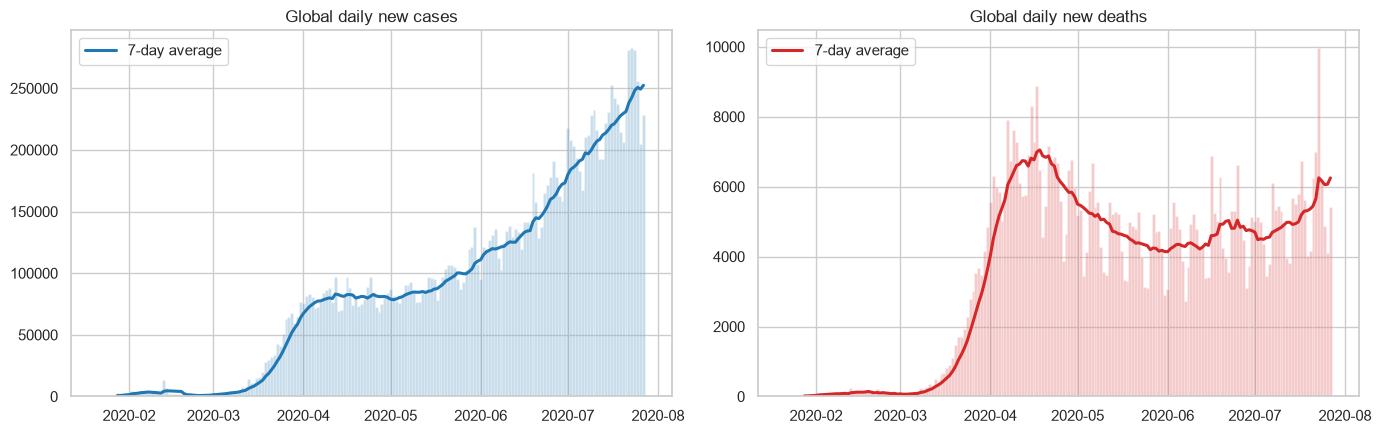

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (col, ma, color) in zip(axes, [("New cases", "New cases 7d MA", "#1f77b4"),
                                        ("New deaths", "New deaths 7d MA", "#d62728")]):
    ax.bar(glob_ts.index, glob_ts[col], color=color, alpha=.25, width=1)
    ax.plot(glob_ts.index, glob_ts[ma], color=color, lw=2.2, label="7-day average")
    ax.set_title(f"Global daily {col.lower()}"); ax.legend()
plt.tight_layout(); plt.show()

**Reading:** peaks in the moving average mark waves; deaths typically lag cases by 1–3 weeks.

### 5.3 Country-wise ranking – horizontal bars (best for ranking categories)

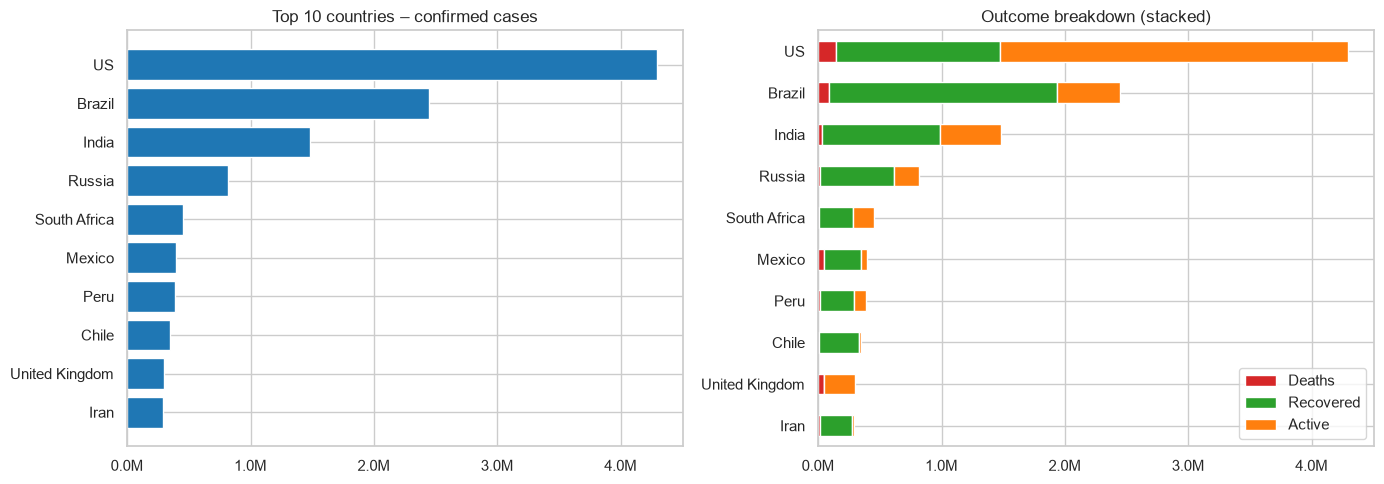

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = top10.sort_values("Confirmed")
axes[0].barh(order["Country"], order["Confirmed"], color="#1f77b4")
axes[0].set_title("Top 10 countries – confirmed cases")
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
stack = order.set_index("Country")[["Deaths", "Recovered", "Active"]].clip(lower=0)
stack.plot.barh(stacked=True, ax=axes[1], color=["#d62728", "#2ca02c", "#ff7f0e"])
axes[1].set_title("Outcome breakdown (stacked)"); axes[1].set_ylabel("")
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
plt.tight_layout(); plt.show()

### 5.4 Fatality vs recovery rate – scatter (relationship between two ratios, bubble = size)

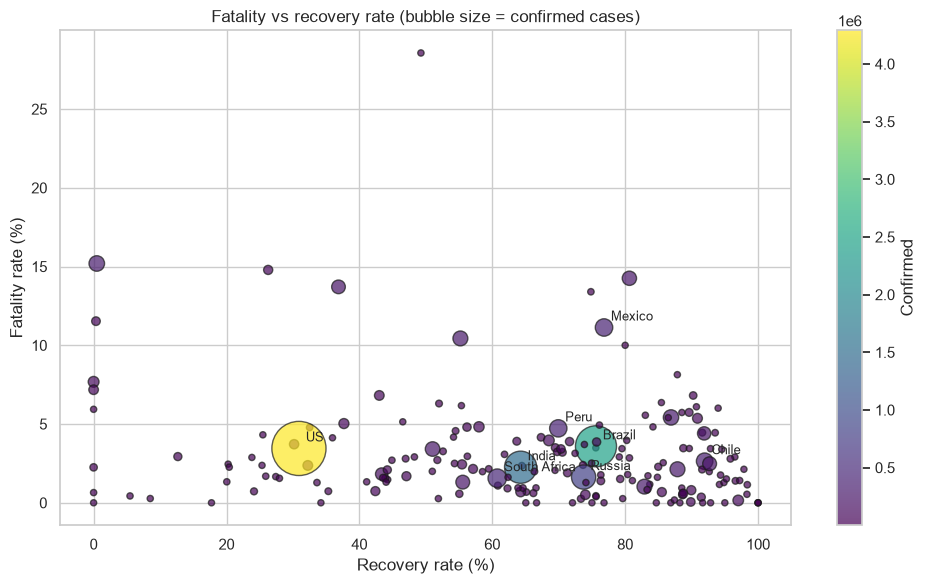

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(latest["Recovery rate %"], latest["Fatality rate %"], s=latest["Confirmed"] / latest["Confirmed"].max() * 1500 + 20,
                c=latest["Confirmed"], cmap="viridis", alpha=.7, edgecolor="k")
for _, r in latest.nlargest(8, "Confirmed").iterrows():
    ax.annotate(r["Country"], (r["Recovery rate %"], r["Fatality rate %"]), xytext=(5, 5), textcoords="offset points", fontsize=9)
ax.set_xlabel("Recovery rate (%)"); ax.set_ylabel("Fatality rate (%)")
ax.set_title("Fatality vs recovery rate (bubble size = confirmed cases)")
plt.colorbar(sc, label="Confirmed"); plt.tight_layout(); plt.show()

### 5.5 Trajectories of the 5 worst-hit countries – log-scale lines (compare growth rates)

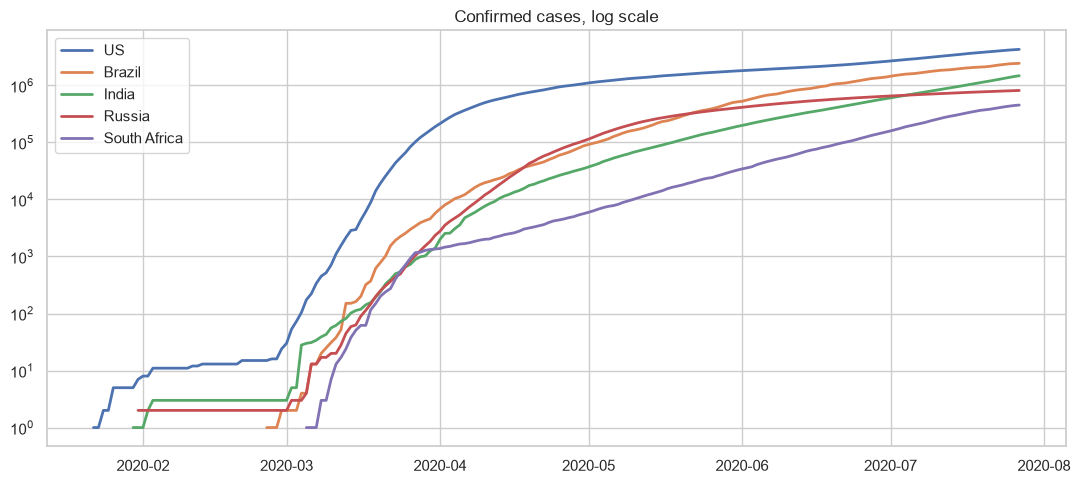

In [11]:
top5 = top10["Country"].head(5).tolist()
fig, ax = plt.subplots(figsize=(11, 5))
for c in top5:
    d = full[full["Country"] == c]
    ax.plot(d["Date"], d["Confirmed"].replace(0, np.nan), label=c, lw=2)
ax.set_yscale("log"); ax.set_title("Confirmed cases, log scale"); ax.legend()
plt.tight_layout(); plt.show()

**Reading:** on a log axis, straight lines mean exponential growth; flattening lines show successful containment.

### 5.6 WHO region share – donut + region totals

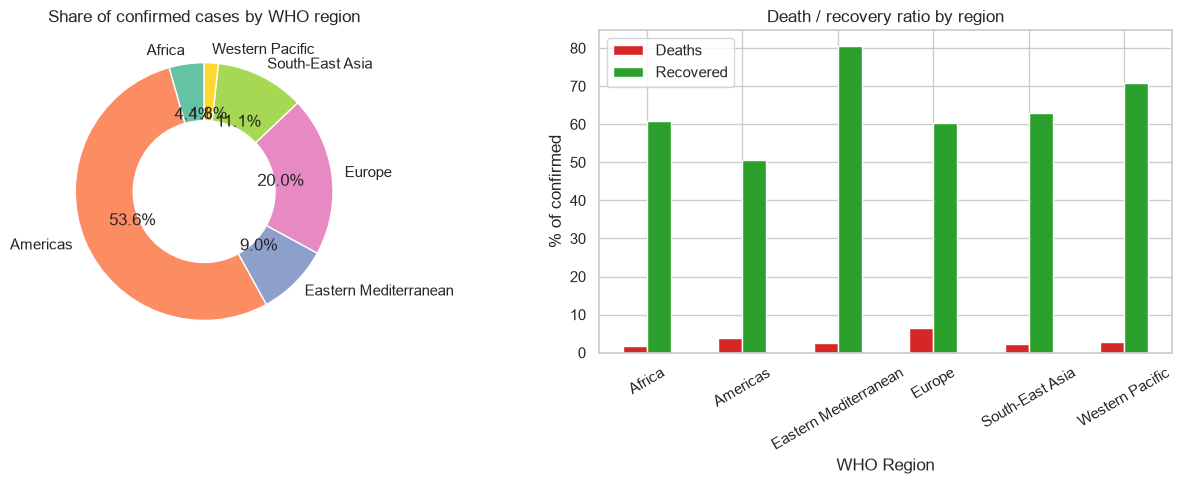

In [12]:
if "WHO Region" in latest:
    reg = latest.groupby("WHO Region")[["Confirmed", "Deaths", "Recovered"]].sum()
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    axes[0].pie(reg["Confirmed"], labels=reg.index, autopct="%1.1f%%", startangle=90,
                wedgeprops=dict(width=.45), colors=sns.color_palette("Set2"))
    axes[0].set_title("Share of confirmed cases by WHO region")
    (reg[["Deaths", "Recovered"]] / reg["Confirmed"].values[:, None] * 100).plot.bar(ax=axes[1], color=["#d62728", "#2ca02c"])
    axes[1].set_ylabel("% of confirmed"); axes[1].set_title("Death / recovery ratio by region"); axes[1].tick_params(axis="x", rotation=30)
    plt.tight_layout(); plt.show()

### 5.7 Vaccination trends

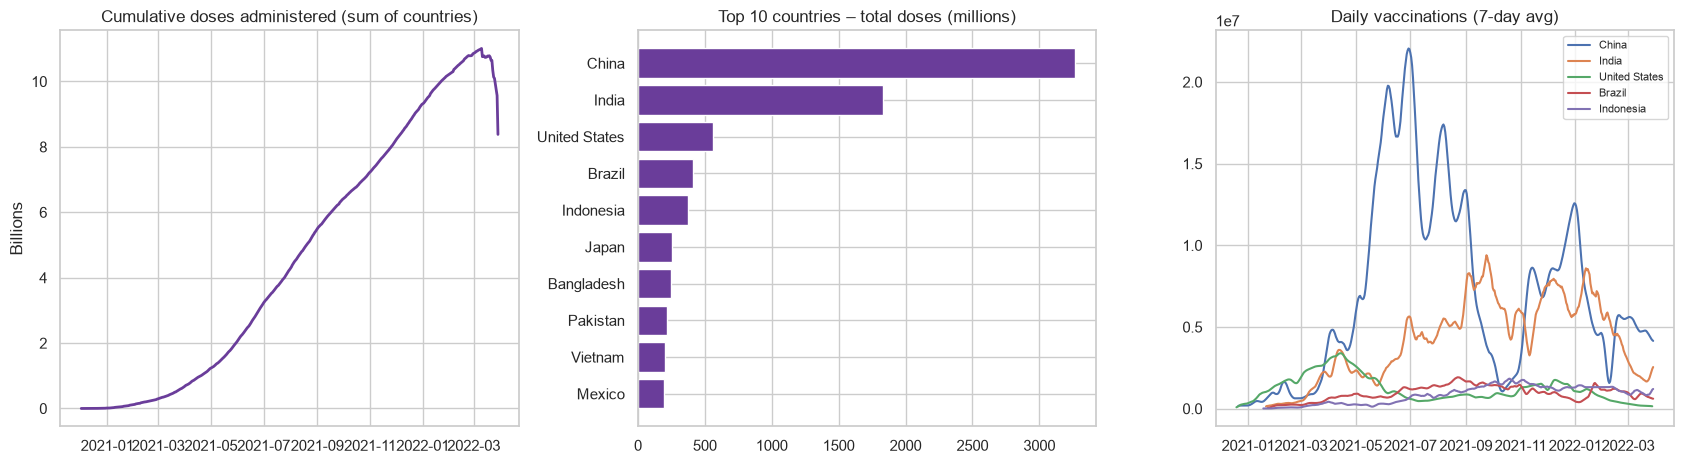

In [13]:
vlast = vac.sort_values("date").groupby("country").tail(1)
glob_vac = vac.groupby("date")[["total_vaccinations", "daily_vaccinations"]].sum()
topv = vlast.nlargest(10, "total_vaccinations")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].plot(glob_vac.index, glob_vac["total_vaccinations"] / 1e9, color="#6a3d9a", lw=2)
axes[0].set_title("Cumulative doses administered (sum of countries)"); axes[0].set_ylabel("Billions")
axes[1].barh(topv.sort_values("total_vaccinations")["country"], topv.sort_values("total_vaccinations")["total_vaccinations"] / 1e6, color="#6a3d9a")
axes[1].set_title("Top 10 countries – total doses (millions)")
for c in topv["country"].head(5):
    d = vac[vac["country"] == c]
    axes[2].plot(d["date"], d["daily_vaccinations"].rolling(7).mean(), label=c)
axes[2].set_title("Daily vaccinations (7-day avg)"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

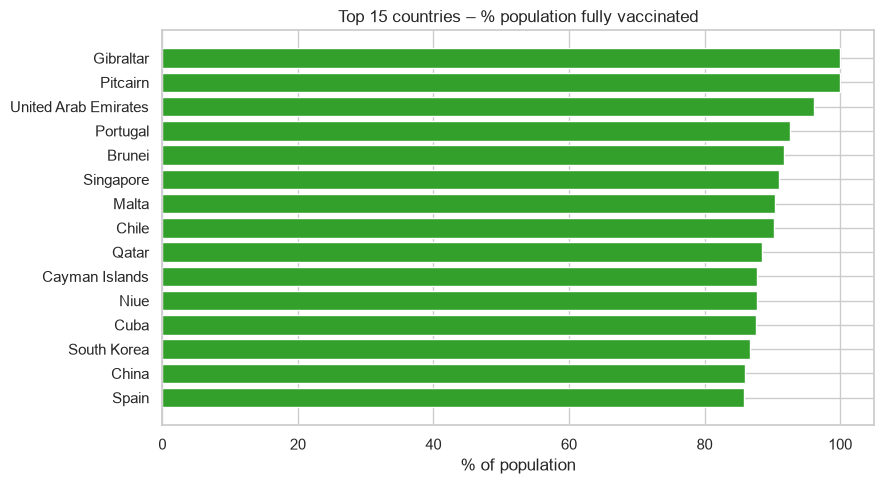

In [14]:
col = "people_fully_vaccinated_per_hundred"
if col in vlast:
    t = vlast.nlargest(15, col).sort_values(col)
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(t["country"], t[col].clip(upper=100), color="#33a02c")
    ax.set_title("Top 15 countries – % population fully vaccinated"); ax.set_xlabel("% of population")
    plt.tight_layout(); plt.show()

### 5.8 Correlation heatmap of country-level indicators

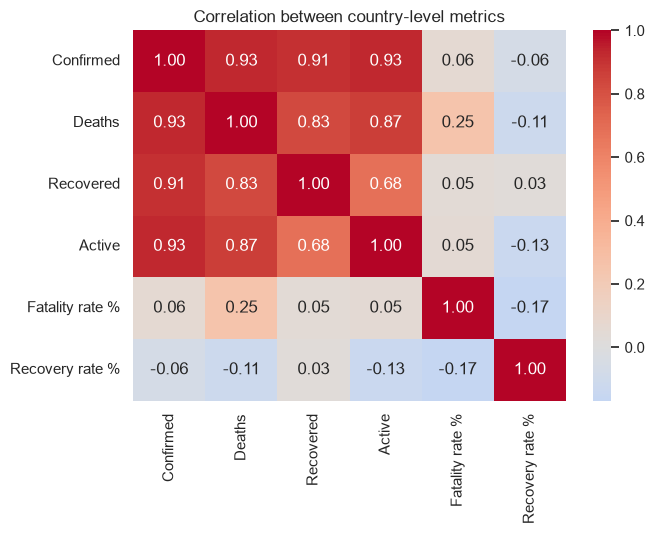

In [15]:
cm = latest[["Confirmed", "Deaths", "Recovered", "Active", "Fatality rate %", "Recovery rate %"]].corr()
plt.figure(figsize=(7, 5.5)); sns.heatmap(cm, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between country-level metrics"); plt.tight_layout(); plt.show()

### 5.9 Interactive charts (Plotly – optional)

In [16]:
try:
    import plotly.express as px
    fig = px.choropleth(latest, locations="Country", locationmode="country names", color="Confirmed",
                        hover_data=["Deaths", "Recovered", "Fatality rate %"], color_continuous_scale="Reds",
                        title="Confirmed cases by country (hover for details)")
    fig.show()
    sel = full[full["Country"].isin(top5)]
    px.line(sel, x="Date", y="Confirmed", color="Country", title="Confirmed cases – top 5 (interactive)").show()
except Exception as exc:
    print("Plotly not available / not rendered:", exc)

Plotly not available / not rendered: No module named 'plotly'


## 6. Combined dashboard (export-ready screenshot)

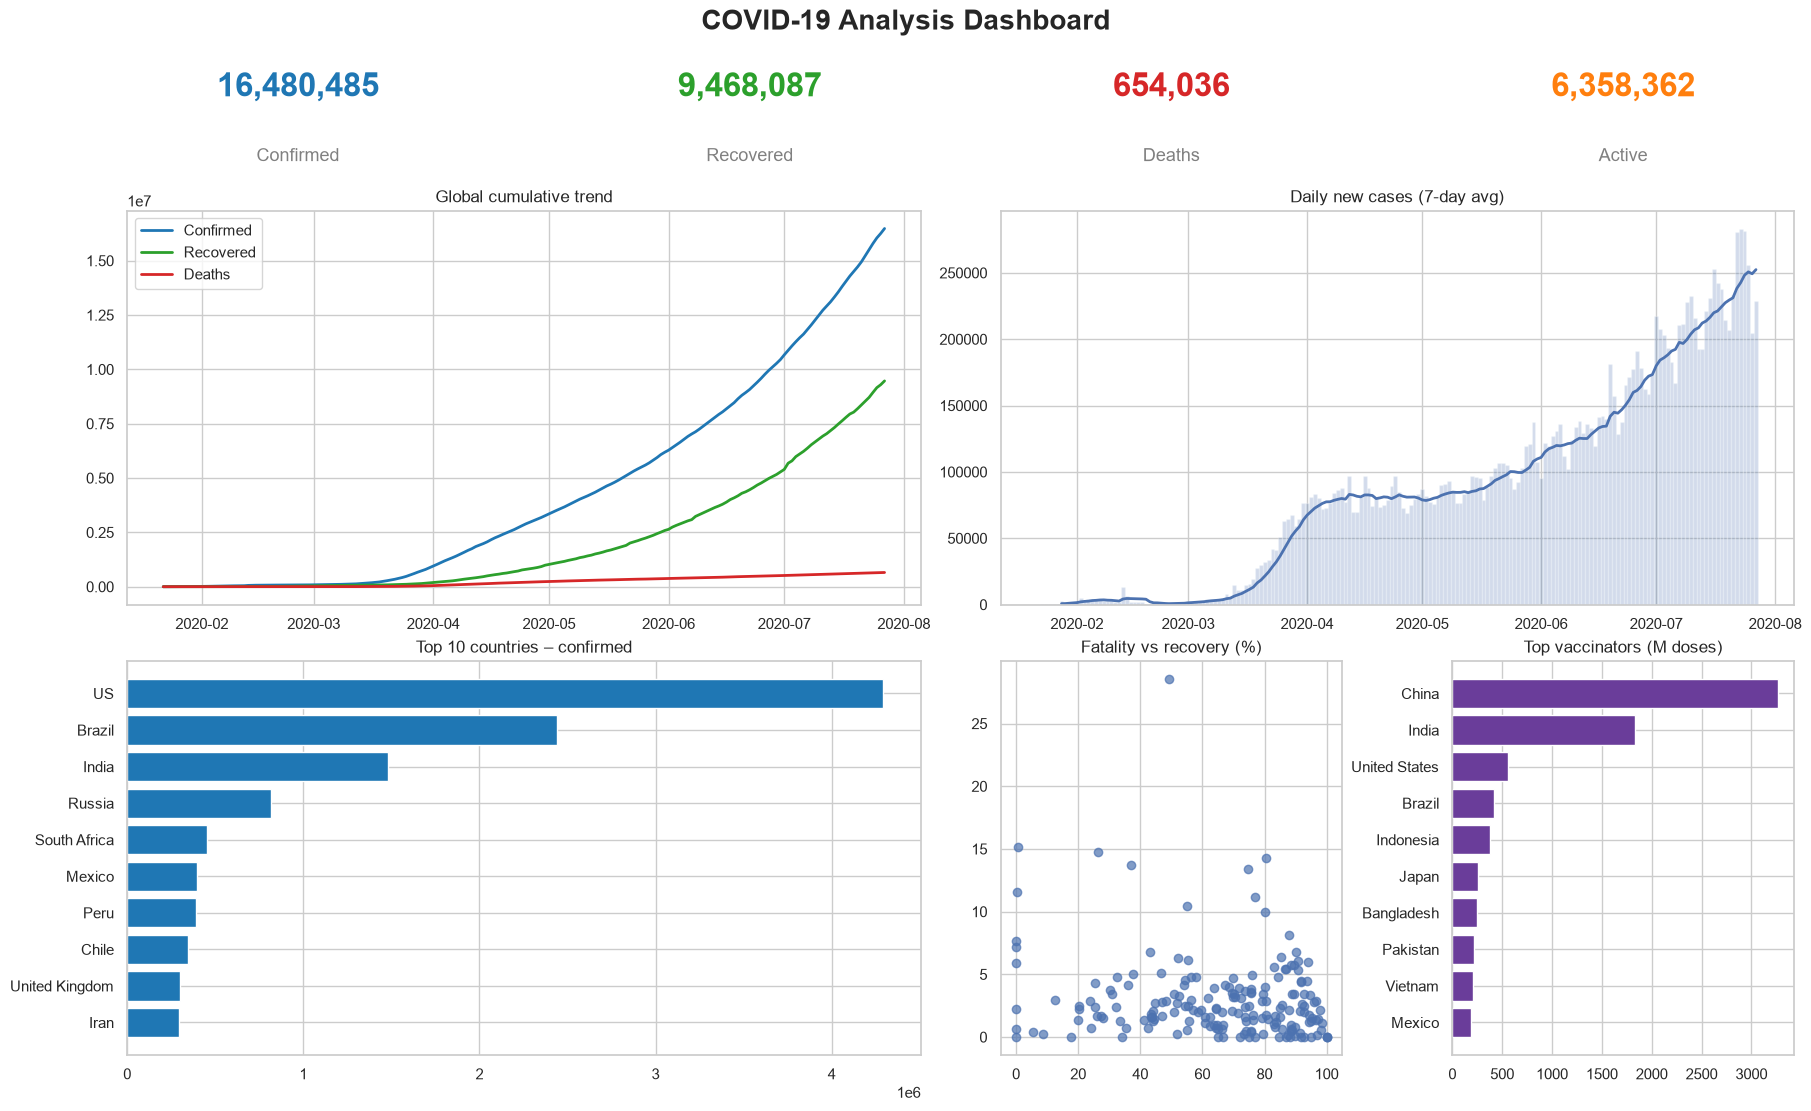

In [18]:
fig = plt.figure(figsize=(18, 11), constrained_layout=True)
gs = fig.add_gridspec(3, 4, height_ratios=[.35, 1, 1])
# KPI tiles
kpis = [("Confirmed", glob_ts["Confirmed"].iloc[-1], "#1f77b4"), ("Recovered", glob_ts["Recovered"].iloc[-1], "#2ca02c"),
        ("Deaths", glob_ts["Deaths"].iloc[-1], "#d62728"), ("Active", glob_ts["Active"].iloc[-1], "#ff7f0e")]
for i, (name, val, color) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i]); ax.axis("off")
    ax.text(.5, .62, f"{val:,.0f}", ha="center", fontsize=24, weight="bold", color=color)
    ax.text(.5, .15, name, ha="center", fontsize=13, color="gray")
ax = fig.add_subplot(gs[1, :2])
for col, color in zip(["Confirmed", "Recovered", "Deaths"], ["#1f77b4", "#2ca02c", "#d62728"]):
    ax.plot(glob_ts.index, glob_ts[col], color=color, label=col, lw=2)
ax.set_title("Global cumulative trend"); ax.legend()
ax = fig.add_subplot(gs[1, 2:])
ax.bar(glob_ts.index, glob_ts["New cases"], alpha=.25, width=1); ax.plot(glob_ts.index, glob_ts["New cases 7d MA"], lw=2)
ax.set_title("Daily new cases (7-day avg)")
ax = fig.add_subplot(gs[2, :2]); o = top10.sort_values("Confirmed"); ax.barh(o["Country"], o["Confirmed"], color="#1f77b4"); ax.set_title("Top 10 countries – confirmed")
ax = fig.add_subplot(gs[2, 2]); ax.scatter(latest["Recovery rate %"], latest["Fatality rate %"], alpha=.7); ax.set_title("Fatality vs recovery (%)")
ax = fig.add_subplot(gs[2, 3]); ax.barh(topv.sort_values("total_vaccinations")["country"], topv.sort_values("total_vaccinations")["total_vaccinations"] / 1e6, color="#6a3d9a"); ax.set_title("Top vaccinators (M doses)")
fig.suptitle("COVID-19 Analysis Dashboard" , fontsize=20, weight="bold")
fig.savefig("covid_dashboard.png", dpi=130); plt.show()

## 7. Summary of findings (computed from the data)

In [ ]:
peak = glob_ts["New cases 7d MA"].idxmax()
worst = latest.nlargest(1, "Confirmed").iloc[0]
highest_cfr = latest[latest["Confirmed"] > 10000].nlargest(1, "Fatality rate %").iloc[0]
print(f"""KEY INSIGHTS ({'DEMO DATA' if DEMO else 'Kaggle data'})
1. As of {last_date.date()}: {glob_ts['Confirmed'].iloc[-1]:,.0f} confirmed, {glob_ts['Deaths'].iloc[-1]:,.0f} deaths, {glob_ts['Recovered'].iloc[-1]:,.0f} recoveries.
2. Global crude fatality rate: {glob_ts['Deaths'].iloc[-1] / glob_ts['Confirmed'].iloc[-1] * 100:.2f}%; recovery rate: {glob_ts['Recovered'].iloc[-1] / glob_ts['Confirmed'].iloc[-1] * 100:.2f}%.
3. Peak of the 7-day average of daily new cases: {glob_ts['New cases 7d MA'].max():,.0f} on {peak.date()}.
4. Most affected country: {worst['Country']} ({worst['Confirmed']:,.0f} cases); top-5 countries hold {top10['Confirmed'].head(5).sum() / latest['Confirmed'].sum() * 100:.1f}% of all cases.
5. Highest fatality rate (>10k cases): {highest_cfr['Country']} at {highest_cfr['Fatality rate %']:.2f}%.
6. Leader in total vaccine doses: {topv.iloc[0]['country']} ({topv.iloc[0]['total_vaccinations'] / 1e6:,.1f}M doses).""")

### Interpretation notes
* Confirmed counts depend on testing capacity; fatality rate here is the *crude* ratio, not the true infection fatality rate.
* Log-scale lines and 7-day averages were used to avoid misleading readings from reporting spikes.
* Forward-filling cumulative vaccination figures is reasonable; per-day figures were left as 0 where unreported.
* **Limitations:** the case dataset ends mid-2020 while the vaccination dataset starts Dec 2020, so they are analysed side by side, not merged.
